# Math 465 Fall 2026

## Module 3. Demo 1: MDS and Isomap

Xiuyuan Cheng  
xiuyuan.cheng@duke.edu

This notebook demonstrates:

- metric MDS and PCA on handwritten digit images;
- the connection between centered SVD and PCA from Module 2;
- Isomap on the digit images and sensitivity to the number of neighbors;
- the distinction between stress minimization and classical MDS.

Labels are used only to color the plots. All data are generated locally or included with scikit-learn.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.manifold import MDS, Isomap
from sklearn.neighbors import kneighbors_graph
from scipy.sparse.csgraph import connected_components

### Example 1. Metric MDS on digit images

For dissimilarities $\delta_{ij}$ and embedding coordinates $z_i\in\mathbb{R}^2$, metric MDS minimizes the raw stress

$$C(Z)=\sum_{i<j}\left(\delta_{ij}-\|z_i-z_j\|_2\right)^2.$$

Here $\delta_{ij}$ is the Euclidean distance between two pixel vectors. The objective is nonconvex and is optimized by stress majorization (SMACOF).

Classical MDS instead minimizes **strain**, a discrepancy between centered Gram matrices. For Euclidean input distances it recovers PCA coordinates, up to rotations and reflections. Metric MDS can give a different embedding. Non-metric MDS additionally fits a monotone transformation of the dissimilarities; we do not use it here.

See the [MDS documentation](https://scikit-learn.org/stable/modules/generated/sklearn.manifold.MDS.html).

#### Load and inspect the images

The UCI digits data set contains 1,797 images with 8 by 8 pixels. We use the first 1,000 images, with their original pixel scale. This is the same small digit data set used in HW2; it is separate from 28 by 28 MNIST.

Digit data matrix: (1000, 64)


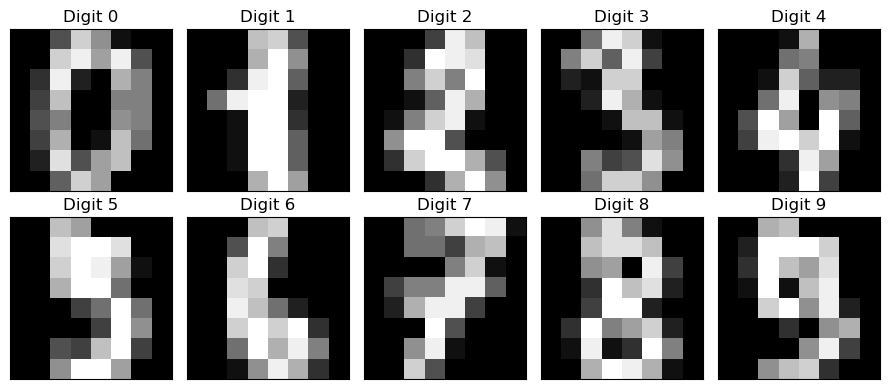

In [2]:
n_digits = 1000
all_digits, all_digit_labels = load_digits(return_X_y=True)
X_digits = all_digits[:n_digits]
y_digits = all_digit_labels[:n_digits]
print('Digit data matrix:', X_digits.shape)

fig, axes = plt.subplots(2, 5, figsize=(9, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(X_digits[i].reshape(8, 8), cmap='gray', vmin=0, vmax=16)
    ax.set_title(f'Digit {y_digits[i]}')
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

#### Fit metric MDS

We explicitly use random initialization and select the best of four starts. `normalized_stress=False` reports the raw sum of squared distance errors above. The maximum iteration count is a cap, not a convergence guarantee.

This is the main computation in this example. Check its reported runtime, stress, and iteration count before comparing the plots.

In [3]:
mds_digits = MDS(
    n_components=2, init='random', n_init=4, random_state=2026,
    max_iter=1000, normalized_stress=False
)
start = time.perf_counter()
Z_mds = mds_digits.fit_transform(X_digits)
mds_seconds = time.perf_counter() - start

print(f'Metric MDS: {mds_seconds:.2f} seconds')
print(f'Raw stress: {mds_digits.stress_:,.1f}')
print(f'Iterations in selected run: {mds_digits.n_iter_}/{mds_digits.max_iter}')
if mds_digits.n_iter_ < mds_digits.max_iter:
    print('The selected run met the stopping tolerance.')
else:
    print('Iteration cap reached; convergence is not established.')

Metric MDS: 17.86 seconds
Raw stress: 128,520,785.3
Iterations in selected run: 556/1000
The selected run met the stopping tolerance.


#### Compare with PCA/centered SVD

Use exactly the same images for all three calculations. PCA centers the features automatically. For truncated SVD, we center explicitly, as in Module 2.

The SVD calculation below uses the same ARPACK solver as the PCA demos, with a fixed seed. Signs of the returned directions can differ without changing the geometry.

In [4]:
start = time.perf_counter()
pca_digits = PCA(n_components=2, svd_solver='full')
Z_pca = pca_digits.fit_transform(X_digits)
pca_seconds = time.perf_counter() - start

start = time.perf_counter()
X_digits_centered = X_digits - X_digits.mean(axis=0)
svd_digits = TruncatedSVD(n_components=2, algorithm='arpack', random_state=2026)
Z_svd = svd_digits.fit_transform(X_digits_centered)
svd_seconds = time.perf_counter() - start

print(f'PCA: {pca_seconds:.3f} seconds')
print(f'Centered truncated SVD: {svd_seconds:.3f} seconds')
print('PCA singular values:', np.round(pca_digits.singular_values_, 3))
print('SVD singular values:', np.round(svd_digits.singular_values_, 3))

PCA: 0.019 seconds
Centered truncated SVD: 0.003 seconds
PCA singular values: [411.328 399.489]
SVD singular values: [411.328 399.489]


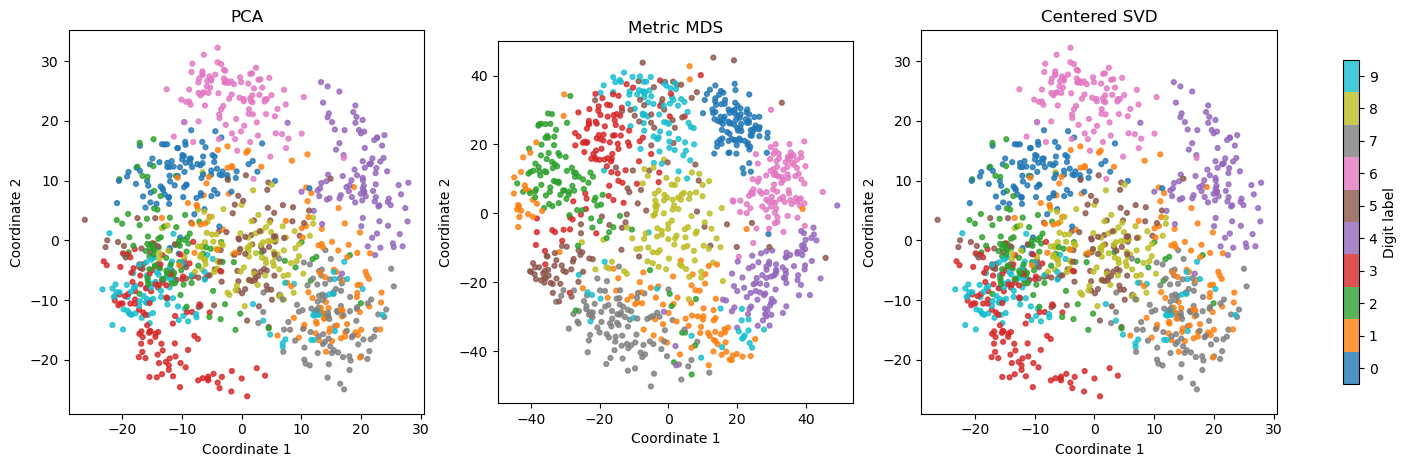

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), layout='constrained')
for ax, embedding, title in zip(
    axes, [Z_pca, Z_mds, Z_svd], ['PCA', 'Metric MDS', 'Centered SVD']
):
    points = ax.scatter(
        embedding[:, 0], embedding[:, 1], c=y_digits,
        cmap='tab10', vmin=-0.5, vmax=9.5, s=12, alpha=0.8
    )
    ax.set(xlabel='Coordinate 1', ylabel='Coordinate 2', title=title)
    ax.set_aspect('equal', adjustable='box')
cbar = fig.colorbar(points, ax=axes, ticks=np.arange(10), shrink=0.8)
cbar.set_label('Digit label')
plt.show()

#### Interpretation questions

- Why do PCA and centered SVD give the same geometry, allowing for signs or rotations?
- Why can metric MDS give a different arrangement?
- Does meeting the stopping tolerance imply that MDS found the global minimum?
- Are all ten digits cleanly separated in two dimensions?

A lower metric-MDS stress means better matching of the specified distances; it does not directly measure separation of the digit classes.

### Example 2. Isomap on digit images

Isomap constructs a neighborhood graph, uses Euclidean edge lengths to compute shortest-path distances, and applies **classical MDS** to that distance matrix.

Reuse the 1,000 digit images from Example 1 and vary only the neighborhood size. This keeps the data fixed while we compare how the neighborhood graph changes the embedding.

Digit labels are used only to color the plots. Isomap does not use them when constructing the neighborhood graph or the embedding. Unlike the Swiss roll, these real data have no known correct two-dimensional geometry.

In [7]:
X_isomap = X_digits
y_isomap = y_digits
print('Isomap data matrix:', X_isomap.shape)
print('The labels are retained only for coloring the plots.')

Isomap data matrix: (1000, 64)
The labels are retained only for coloring the plots.


#### Vary the number of neighbors

We use the symmetric-union graph: two points are connected if either is among the other's nearest neighbors. We first check connectivity. A disconnected graph has infinite distances between components and is not suitable for this Isomap calculation.

For connected graphs, smaller neighborhoods emphasize local relationships, while larger neighborhoods make the graph closer to the ambient Euclidean geometry. The useful range of $k$ depends on the sample size, noise, and geometry. Because these digit data have no known intrinsic coordinates, compare stability and visible structure rather than looking for one provably correct embedding.

In [8]:
neighbor_counts = [10, 20, 30, 50]
isomap_models = {}
graph_components = {}

for k in neighbor_counts:
    graph = kneighbors_graph(X_isomap, n_neighbors=k, mode='distance')
    graph = graph.maximum(graph.T)
    n_components = connected_components(graph, directed=False, return_labels=False)
    graph_components[k] = n_components
    if n_components != 1:
        print(f'k={k}: {n_components} components; skip Isomap')
        continue
    start = time.perf_counter()
    model = Isomap(n_neighbors=k, n_components=2)
    model.fit(X_isomap)
    isomap_models[k] = model
    print(f'k={k}: connected; Isomap took {time.perf_counter() - start:.3f} seconds')

k=10: connected; Isomap took 0.095 seconds
k=20: connected; Isomap took 0.112 seconds
k=30: connected; Isomap took 0.134 seconds
k=50: connected; Isomap took 0.175 seconds


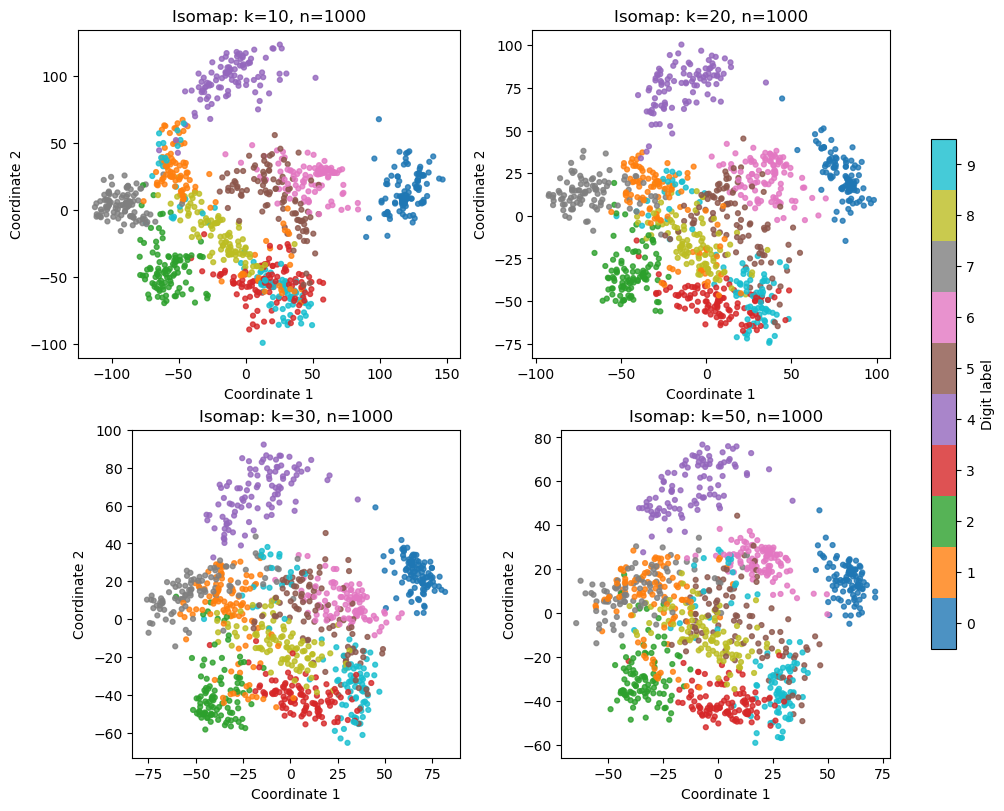

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8), layout='constrained')
for ax, k in zip(axes.flat, neighbor_counts):
    ax.set_title(f'Isomap: k={k}, n={X_isomap.shape[0]}')
    if k not in isomap_models:
        ax.text(0.5, 0.5, f'{graph_components[k]} connected components',
                ha='center', va='center', transform=ax.transAxes)
        ax.set_axis_off()
        continue
    embedding = isomap_models[k].embedding_
    points = ax.scatter(embedding[:, 0], embedding[:, 1],
                        c=y_isomap, cmap='tab10',
                        vmin=-0.5, vmax=9.5, s=12, alpha=0.8)
    ax.set(xlabel='Coordinate 1', ylabel='Coordinate 2')
    ax.set_aspect('equal', adjustable='box')
fig.colorbar(points, ax=axes, ticks=np.arange(10),
             shrink=0.7, label='Digit label')
plt.show()

#### Interpretation questions

- Which digit groups remain visually stable as $k$ changes?
- What changes as the neighborhood graph becomes denser?
- What would go wrong if the neighborhood graph were disconnected?
- Why should we reconsider $k$ when the sample size changes?
- Why do colored groups not prove that the data consist of ten well-separated manifolds?